# Tópico 3 - Transformada Discreta de Fourier (DFT)

## Visão Geral e Objetivos
Neste notebook, investigamos a **Transformada Discreta de Fourier (DFT)** aplicada a sinais discretos de duração finita $N$. Os principais objetivos são:
1. **Formulação da DFT**: Implementar o cálculo dos coeficientes espectrais $X[k] = \sum_{n=0}^{N-1} x[n] e^{-j \frac{2\pi}{N} k n}$ para $k = 0, 1, \dots, N-1$.
2. **Sintese de Sinal Multi-Senoidal**: Gerar um sinal composto pela soma de duas senoides de frequências distintas $x[n] = A_1 \cos(\omega_1 n) + A_2 \cos(\omega_2 n)$.
3. **Análise de Magnitude e Fase**: Extrair e visualizar o espectro discreto de magnitude $|X[k]|$ e fase $\angle X[k]$.
4. **Mapeamento de Picos e Frequências**: Relacionar os picos observados no espectro discreto $k$ com as frequências angulares teóricas $\omega_1$ e $\omega_2$.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Garantir a criação do diretório local para salvar as imagens do gráfico
os.makedirs(".", exist_ok=True)

## 1. Geração do Sinal Multi-Senoidal no Domínio do Tempo

Geramos um sinal discreto composto por duas senoides com amplitudes e frequências distintas [1]:
$$x[n] = A_1 \cos(\omega_1 n) + A_2 \cos(\omega_2 n)$$

Parâmetros adotados:
- Número de amostras: $N = 64$
- Componente 1: $A_1 = 1.5$, $\omega_1 = 0.2\pi$ rad/amostra (frequência bin $k_1 = \frac{\omega_1 N}{2\pi} = 6.4 \approx 6$)
- Componente 2: $A_2 = 0.8$, $\omega_2 = 0.5\pi$ rad/amostra (frequência bin $k_2 = \frac{\omega_2 N}{2\pi} = 16$)

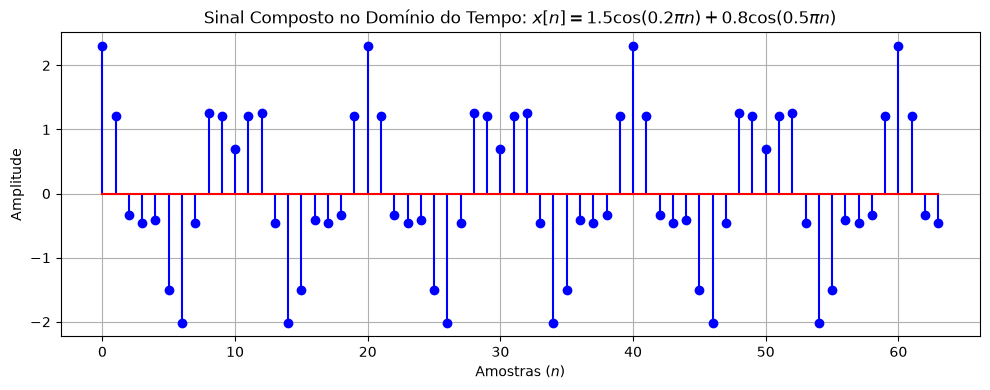

In [2]:
# Parâmetros do sinal
N = 64
n = np.arange(0, N)

# Parâmetros das componentes senoidais
A1, w1 = 1.5, 0.2 * np.pi
A2, w2 = 0.8, 0.5 * np.pi

# Geração do sinal composto x[n]
x = A1 * np.cos(w1 * n) + A2 * np.cos(w2 * n)

# Plotagem do sinal no domínio do tempo
fig1, ax1 = plt.subplots(figsize=(10, 4))
ax1.stem(n, x, linefmt='b-', markerfmt='bo', basefmt='r-')
ax1.set_title(r'Sinal Composto no Domínio do Tempo: $x[n] = 1.5\cos(0.2\pi n) + 0.8\cos(0.5\pi n)$')
ax1.set_xlabel('Amostras ($n$)')
ax1.set_ylabel('Amplitude')
ax1.grid(True)

plt.tight_layout()
fig1.savefig("grafico_sinal_tempo_dft.png")
plt.show()

## 2. Cálculo da Transformada Discreta de Fourier (DFT)

A DFT converte a sequência de $N$ amostras temporais $x[n]$ em $N$ coeficientes espectrais complexos $X[k]$ [1]:
$$X[k] = \sum_{n=0}^{N-1} x[n] e^{-j \frac{2\pi}{N} k n}, \quad k = 0, 1, \dots, N-1$$

Abaixo, implementamos a equação direta da DFT por meio da matriz de transformação exponencial.

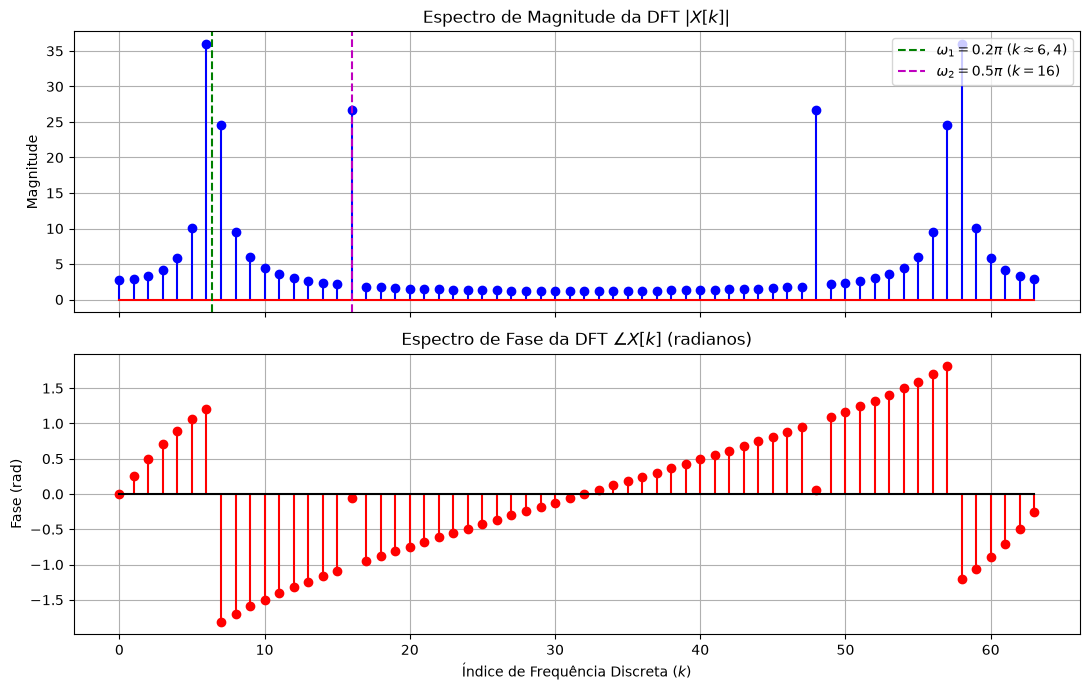

In [3]:
# Índices k de frequência discreta
k = np.arange(0, N)

# Matriz da DFT: W[k, n] = exp(-j * 2*pi * k * n / N)
n_mat, k_mat = np.meshgrid(n, k)
W_N = np.exp(-1j * 2 * np.pi * k_mat * n_mat / N)

# Cálculo da DFT: X[k] = sum_n (x[n] * W_N[k, n])
X_dft = np.dot(W_N, x)

# Magnitude e Fase
magnitude = np.abs(X_dft)
fase = np.angle(X_dft)

# Frequências angulares associadas aos bins k: w_k = 2*pi*k / N
w_k = 2 * np.pi * k / N

# Plotagem dos Espectros de Magnitude e Fase
fig2, (ax_mag, ax_fase) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# Subplot 1: Espectro de Magnitude
ax_mag.stem(k, magnitude, linefmt='b-', markerfmt='bo', basefmt='r-')
ax_mag.set_title(r'Espectro de Magnitude da DFT $|X[k]|$')
ax_mag.set_ylabel('Magnitude')
ax_mag.grid(True)

# Destacar os picos esperados
ax_mag.axvline(x=6.4, color='g', linestyle='--', label=r'$\omega_1 = 0.2\pi$ ($k \approx 6,4$)')
ax_mag.axvline(x=16, color='m', linestyle='--', label=r'$\omega_2 = 0.5\pi$ ($k = 16$)')
ax_mag.legend(loc='upper right')

# Subplot 2: Espectro de Fase
ax_fase.stem(k, fase, linefmt='r-', markerfmt='ro', basefmt='k-')
ax_fase.set_title(r'Espectro de Fase da DFT $\angle X[k]$ (radianos)')
ax_fase.set_xlabel('Índice de Frequência Discreta ($k$)')
ax_fase.set_ylabel('Fase (rad)')
ax_fase.grid(True)

plt.tight_layout()
fig2.savefig("grafico_dft_magnitude_fase.png")
plt.show()

## 3. Análise dos Picos Espectrais e Identificação de Frequências
- **Localização dos Picos**: A primeira frequência ($\omega_1 = 0.2\pi$) corresponde ao índice de frequência $k_1 = \frac{0.2\pi \cdot 64}{2\pi} = 6.4$. Observa-se maior concentração de energia entre os bins $k=6$ e $k=7$.
- **Segundo Pico**: A segunda frequência ($\omega_2 = 0.5\pi$) resulta no bin exato $k_2 = \frac{0.5\pi \cdot 64}{2\pi} = 16$, onde é registrado um pico nítido de amplitude proporcional a $\frac{A_2 N}{2} = \frac{0.8 \cdot 64}{2} = 25.6$.
- **Simetria Conjugada**: Por ser um sinal real no tempo, a DFT exibe simetria hermitiana: $|X[k]| = |X[N-k]|$ e $\angle X[k] = -\angle X[N-k]$.